# EA3 - Aprendizaje supervisado: ¿qué caballos terminan en posición de pago?

**Dataset:** [`mayacheruty/Horse-Race-Prediction-EDA`](https://huggingface.co/datasets/mayacheruty/Horse-Race-Prediction-EDA) (Hugging Face) · **Modelo:** Random Forest (aprendizaje supervisado, clasificación binaria)

Todo el código vive en clases de `src/clases_po/` (`datos_podio.py`, `preprocesamiento_podio.py`, `modelo_random_forest.py`, `graficas_podio.py`, `reporte_podio.py`); este notebook solo las invoca.

| Sección | Contenido |
|---|---|
| 1 | Pregunta de negocio y construcción automática del DataFrame |
| 2 | Preprocesamiento (antes / después, división y sin fuga de información) |
| 3 | Selección del modelo y variables |
| 4 | Entrenamiento, hiperparámetros, métricas y evaluación |
| 5 | Resumen automático `.txt` y documento de hallazgos |

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from clases_po import (
    AlmacenResultados,
    ConsolidadorEA3,
    DatasetPodioCarreras,
    GraficasEA3,
    ModeloPodioRandomForest,
    PreprocesamientoPodio,
    ReporteEA3,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

SALIDA = ROOT / "src" / "sincronicas" / "resultados_ea3"   # resumen, JSON, gráficas y hallazgos
ENTRENAMIENTO = ROOT / "src" / "sincronicas" / "entrenamiento_ea3"
SEMILLA = 42
graficas = GraficasEA3(SALIDA / "graficas")
rutas_graficas = {}

## 1. Pregunta de negocio y construcción automática del DataFrame

**Pregunta de negocio**

> ¿Qué factores conocidos antes de la salida determinan que un caballo termine en posición de pago (podio), para que un analista de apuestas hípicas decida a qué caballos de cada carrera dar prioridad en sus apuestas de colocado?

- **Quién se beneficia:** un analista o apostador de carreras que debe repartir un presupuesto limitado entre los caballos de cada carrera.
- **Decisión que apoya:** elegir qué caballos merecen una apuesta de colocado y qué factores (mercado, rating, peso, edad, tamaño del campo) pesan más en esa elección.

**Dataset:** `mayacheruty/Horse-Race-Prediction-EDA` · configuración `default` · split `train` (único) · archivo `data/horse_racing_cleaned.csv` · licencia MIT. Cada fila es un caballo en una carrera de 2019. Los datos se descargan de Hugging Face al ejecutar; no se carga ningún archivo a mano.

**Por qué sirve para responder la pregunta:** contiene el resultado real (`res_place`), las variables que un analista conoce antes de la salida (precio de mercado, rating oficial, edad, peso, número de corredores) y un identificador de carrera (`rid`) que permite evaluar con carreras no vistas.

**Variable objetivo:** `res_place` ya viene en el dataset (1 = terminó en posición de pago, 0 = no); no se construye a partir de otra variable. Por eso `position`, `res_win`, `margin`, `positionL`, `dist`, `RPR` y `TR` **no pueden ser predictoras**: revelan o se calculan después del resultado.

In [2]:
datos = DatasetPodioCarreras()
df = datos.cargar()
resumen_df = datos.resumen_dataframe(df)
print(datos.informacion())
print(f"Tamaño del DataFrame: {resumen_df['filas']:,} filas x {resumen_df['columnas']} columnas")

{'dataset': 'mayacheruty/Horse-Race-Prediction-EDA', 'config': 'default', 'split': 'train', 'filas': 171849, 'columnas': 24, 'enlace': 'https://huggingface.co/datasets/mayacheruty/Horse-Race-Prediction-EDA', 'archivo_origen': 'data/horse_racing_cleaned.csv', 'licencia': 'MIT (según la ficha oficial de Hugging Face)'}
Tamaño del DataFrame: 171,849 filas x 24 columnas


In [3]:
display(resumen_df["tipos"])

,tipo,nulos,valores_distintos
rid,int64,0,17233
horseName,object,0,41241
age,float64,0,15
saddle,float64,0,41
decimalPrice,float64,0,586
isFav,int64,0,2
trainerName,object,0,3991
jockeyName,object,0,2929
position,int64,0,31
positionL,object,25219,192


In [4]:
display(resumen_df["muestra"])

,rid,horseName,age,saddle,decimalPrice,isFav,trainerName,jockeyName,position,positionL,dist,weightSt,weightLb,RPR,TR,OR,father,mother,gfather,runners,margin,weight,res_win,res_place
0,11499,Picken,4.0,6.0,0.312500,0,J Size,Joao Moreira,1,None,None,8,13,69.0,NaN,54.0,Duporth,Baby Boom,Redoute's Choice,13,1.217349,56,1.0,1
1,11499,Noble De Love,6.0,7.0,0.333333,1,F C Lor,Zac Purton,2,nk,None,8,12,67.0,NaN,53.0,Commands,Terrenora,Encosta De Lago,13,1.217349,56,0.0,1
2,11499,Fresh Power,5.0,3.0,0.200000,0,Y S Tsui,Silvestre De Sousa,3,2.5,2.75,9,1,63.0,NaN,56.0,Makfi,Bannisters,Redoute's Choice,13,1.217349,57,0.0,1
3,11499,Happy Hour,4.0,5.0,0.017544,0,C H Yip,Umberto Rispoli,4,1.25,4.0,8,13,58.0,NaN,54.0,Mastercraftsman,Jolly Genie,Generous,13,1.217349,56,0.0,0
4,11499,Super Fun,5.0,8.0,0.090909,0,L Ho,Matthew Poon,5,1,5.0,8,9,54.0,NaN,53.0,Dandy Man,Dame Hester,Diktat,13,1.217349,54,0.0,0
5,11499,Blizzing Away,3.0,11.0,0.004587,0,P F Yiu,K C Leung,6,.5,5.5,8,8,49.0,NaN,49.0,All Too Hard,Quackquack,Starcraft,13,1.217349,54,0.0,0
6,11499,Multigogo,5.0,1.0,0.029412,0,A S Cruz,Alberto Sanna,7,nk,5.75,9,5,59.0,NaN,60.0,Drumbeats,Lights Off,Way Of Light,13,1.217349,59,0.0,0
7,11499,Virtus Star,3.0,12.0,0.027027,0,D J Hall,Chad Schofield,8,shd,6.0,8,7,47.0,NaN,48.0,Sebring,Princess Natural,Danehill Dancer,13,1.217349,53,0.0,0


### 1.1 Rol de cada columna y verificación del objetivo

In [5]:
display(datos.tabla_columnas())

,rol,motivo
columna,,
rid,Agrupación,Identifica la carrera; sirve para dividir trai...
res_place,Objetivo,"1 si el caballo terminó en posición de pago, 0..."
decimalPrice,Predictora,Probabilidad implícita del mercado de apuestas...
OR,Predictora,Rating oficial previo a la carrera (con valore...
age,Predictora,Edad del caballo
weight,Predictora,Peso que carga el caballo
runners,Predictora,Número de corredores: define el tamaño del campo
saddle,Predictora,Número de silla o puesto de salida (0 = dato f...
position,Excluida (fuga),Posición final: revela el objetivo


In [6]:
display(datos.verificar_objetivo(df))

/workspaces/ML_2026_IUD/src/clases_po/datos_podio.py:148: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  tabla["porcentaje"] = (tabla["filas"] / tabla["filas"].sum() * 100).round(2)


,clase,filas,posicion_minima,posicion_mediana,posicion_maxima,porcentaje
res_place,,,,,,
0,Fuera del podio,124453,2,7.0,40,72.42
1,En posición de pago,47396,1,2.0,4,27.58


## 2. Preprocesamiento

### 2.1 Estado inicial

In [7]:
prep = PreprocesamientoPodio(columna_grupo="rid", test_size=0.2, random_state=SEMILLA)
print("Filas duplicadas:", int(df.duplicated().sum()))
display(prep.diagnosticar(df))
display(prep.detectar_imputados(df, columnas=["OR"]))

Filas duplicadas: 0


,tipo,nulos,pct_nulos,distintos
rid,int64,0,0.00,17233
horseName,object,0,0.00,41241
age,float64,0,0.00,15
saddle,float64,0,0.00,41
decimalPrice,float64,0,0.00,586
isFav,int64,0,0.00,2
trainerName,object,0,0.00,3991
jockeyName,object,0,0.00,2929
position,int64,0,0.00,31
positionL,object,25219,14.68,192


,valores_imputados,pct_imputados,valores_decimales_distintos,valor_imputado
columna,,,,
OR,69860,40.65,1,81.516311


,clase,filas,porcentaje
valor,,,
0,Fuera del podio,124453,72.42
1,En posición de pago,47396,27.58


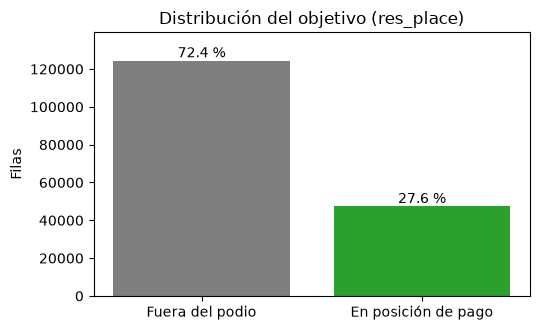

In [8]:
distribucion = PreprocesamientoPodio.distribucion_clases(df["res_place"].astype(int), datos.CLASES)
display(distribucion)
rutas_graficas["distribucion_clases"] = graficas.distribucion_clases(distribucion)

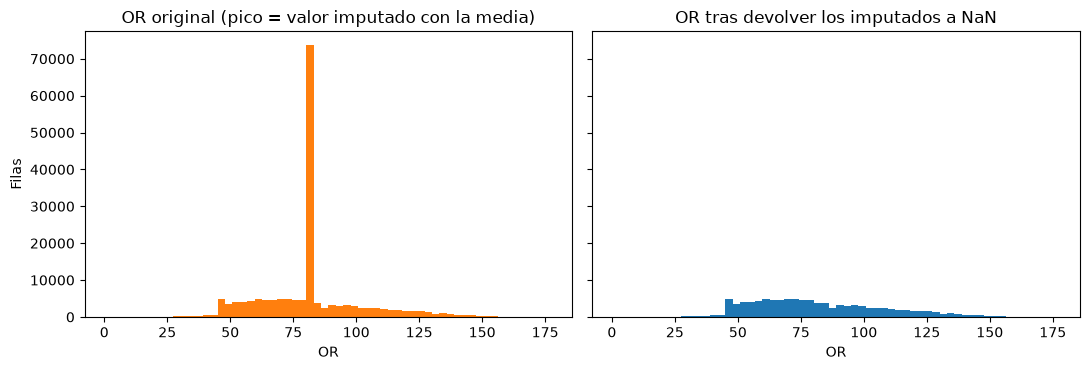

In [9]:
or_restaurado = prep.restaurar_nulos_imputados(df, columnas=["OR"])["OR"]   # solo para la gráfica
rutas_graficas["antes_despues_or"] = graficas.antes_despues_or(df["OR"], or_restaurado)

### 2.2 Limpieza, enriquecimiento y selección de variables

Qué problema resuelve cada operación (también queda en la bitácora de abajo):

- **Duplicados:** filas repetidas contarían dos veces en el entrenamiento.
- **`OR` imputado con la media:** el autor del dataset rellenó los vacíos con un único valor; crea un pico artificial. Se devuelve a nulo y se marca con `OR_faltante`.
- **`saddle = 0`:** es un marcador de "sin dato", no un puesto real.
- **Variables relativas a la carrera** (`prob_mercado_norm`, `rank_mercado`, `weight_rel`, `OR_rel`): un precio o un peso solo informan al compararse con los rivales de la misma carrera. Todas se conocen antes de la salida.
- **Texto de alta cardinalidad** (nombres de caballo, jinete, entrenador, padres): se excluye; miles de valores distintos con pocas filas cada uno.
- **Sin escalado:** el Random Forest divide por umbrales, así que reescalar las variables no cambia el modelo (a diferencia de K-means, KNN o SVM).

In [10]:
X, y, grupos = prep.preparar_podio(df, objetivo=datos.OBJETIVO)
display(prep.resumen_operaciones())

[preparar_podio] 11 predictoras; y='res_place'; 171849 filas de 171849; 17233 carreras.


/workspaces/ML_2026_IUD/src/clases_po/preprocesamiento_podio.py:132: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  sel[objetivo] = sel[objetivo].astype(int)


,operacion,problema_que_resuelve,filas_antes,filas_despues,detalle
0,eliminar_duplicados,Filas repetidas que contarían dos veces en el ...,171849,171849,duplicados eliminados: 0
1,restaurar_nulos_imputados,Ratings imputados con la media por el autor de...,171849,171849,valores devueltos a NaN: OR=69860
2,restaurar_saddle_faltante,El autor usó 0 como marcador de 'sin dato' en ...,171849,171849,saddle == 0 devuelto a NaN: 278 filas
3,seleccionar_y_convertir,"Quitar identificadores, texto de alta cardinal...",171849,171849,8 de 24 columnas conservadas
4,descartar_filas_sin_datos_esenciales,El objetivo no debe imputarse y el precio/edad...,171849,171849,nulos por columna: ninguno
5,convertir_objetivo,El objetivo llega como número (0 / 1); el clas...,171849,171849,"'res_place' convertido a entero, clases [0, 1]"
6,enriquecer_variables_relativas,"El precio, el peso y el rating solo informan a...",171849,171849,"creadas: prob_mercado_norm, rank_mercado, weig..."


### 2.3 Comparación antes y después

In [11]:
comparacion = prep.comparar_antes_despues(df, X, y, grupos)
display(comparacion)
display(X.describe().T.round(3))

,antes (original),después (preparado)
filas,171849.00,171849.00
columnas,24.00,11.00
carreras,17233.00,17233.00
filas duplicadas,0.00,0.00
OR imputados con la media,69860.00,0.00
saddle = 0 (sin dato),278.00,0.00
nulos en las predictoras base,0.00,70138.00
% en posición de pago,27.58,27.58


,count,mean,std,min,25%,50%,75%,max
decimalPrice,171849.0,0.120,0.119,0.002,0.038,0.083,0.164,0.962
age,171849.0,4.826,2.160,2.000,3.000,4.000,6.000,16.000
weight,171849.0,60.644,6.603,43.000,56.000,58.000,67.000,79.000
runners,171849.0,11.388,3.950,2.000,8.000,11.000,14.000,40.000
saddle,171571.0,6.525,4.200,1.000,3.000,6.000,9.000,40.000
OR,101989.0,81.516,26.271,1.000,61.000,77.000,99.000,177.000
prob_mercado_norm,171849.0,0.100,0.101,0.001,0.032,0.068,0.133,0.939
rank_mercado,171849.0,5.995,3.842,1.000,3.000,5.000,8.000,40.000
weight_rel,171849.0,-0.000,2.413,-12.417,-1.333,0.071,1.357,11.000
OR_rel,101989.0,-0.000,6.375,-77.333,-3.857,0.286,4.143,52.000


### 2.4 División entrenamiento / prueba e imputación

Se divide por carrera (80 / 20): todos los caballos de una carrera quedan en el mismo conjunto. La mediana para rellenar nulos se aprende **solo con el entrenamiento** y luego se aplica a la prueba.

In [12]:
X_train, X_test, y_train, y_test = prep.dividir_por_carrera(X, y, grupos)
grupos_train, grupos_test = grupos.loc[X_train.index], grupos.loc[X_test.index]
display(pd.Series(prep.info_division, name="división").to_frame())
display(pd.concat({
    "entrenamiento": PreprocesamientoPodio.distribucion_clases(y_train)["porcentaje"],
    "prueba": PreprocesamientoPodio.distribucion_clases(y_test)["porcentaje"],
}, axis=1).rename_axis("res_place"))

[dividir_por_carrera] entrenamiento=137325 filas; prueba=34524 filas; carreras compartidas=0.


,división
filas_entrenamiento,137325.0
filas_prueba,34524.0
carreras_entrenamiento,13786.0
carreras_prueba,3447.0
carreras_compartidas,0.0
test_size,0.2
random_state,42.0


,entrenamiento,prueba
res_place,,
0,72.42,72.42
1,27.58,27.58


In [13]:
X_train_imp, X_test_imp = prep.imputar(X_train, X_test)
display(pd.DataFrame({
    "nulos antes (entrenamiento)": X_train.isna().sum(),
    "nulos después (entrenamiento)": X_train_imp.isna().sum(),
    "nulos antes (prueba)": X_test.isna().sum(),
    "nulos después (prueba)": X_test_imp.isna().sum(),
}))

[imputar] SimpleImputer(mediana) ajustado con entrenamiento y aplicado a prueba.


,nulos antes (entrenamiento),nulos después (entrenamiento),nulos antes (prueba),nulos después (prueba)
decimalPrice,0,0,0,0
age,0,0,0,0
weight,0,0,0,0
runners,0,0,0,0
saddle,226,0,52,0
OR,55809,0,14051,0
prob_mercado_norm,0,0,0,0
rank_mercado,0,0,0,0
weight_rel,0,0,0,0
OR_rel,55809,0,14051,0


## 3. Selección y funcionamiento del modelo

- **Tipo de aprendizaje:** supervisado. Existe una variable conocida que se quiere predecir (`res_place`) y se tienen ejemplos históricos con la respuesta.
- **Modelo:** Random Forest (`RandomForestClassifier`). Reúne muchos árboles de decisión entrenados con muestras distintas y promedia sus votos: entrega una probabilidad de podio por caballo, captura relaciones no lineales (p. ej. un rating alto solo ayuda en campos pequeños), no exige escalar las variables y permite medir la importancia de cada factor, que es justo lo que pide la pregunta.
- **Variables:** ver la lista de abajo. **Objetivo:** `res_place` ∈ {0 = fuera del podio, 1 = en posición de pago}.

La explicación paso a paso del algoritmo, sus parámetros, ventajas y limitaciones está en el `README.md`.

In [14]:
print("Variables del modelo:", list(X_train_imp.columns))
print("Objetivo:", datos.OBJETIVO, datos.CLASES)

Variables del modelo: ['decimalPrice', 'age', 'weight', 'runners', 'saddle', 'OR', 'prob_mercado_norm', 'rank_mercado', 'weight_rel', 'OR_rel', 'OR_faltante']
Objetivo: res_place {0: 'Fuera del podio', 1: 'En posición de pago'}


## 4. Entrenamiento, métricas y evaluación

### 4.1 Selección de hiperparámetros (validación cruzada por carrera, solo con entrenamiento)

Criterio: PR-AUC media (no depende del umbral y es exigente con la clase positiva). Primero se comparan `max_depth` y `min_samples_leaf`; luego `n_estimators` con la mejor pareja.

[seleccionar_hiperparametros] mejor configuración: {'n_estimators': 50, 'max_depth': 8, 'min_samples_leaf': 20}


,max_depth,min_samples_leaf,n_estimators,pr_auc_cv,pr_auc_cv_desv,roc_auc_cv,pr_auc_entrenamiento
0,8,20,100,0.5540,0.0023,0.7639,0.5680
1,12,20,100,0.5539,0.0028,0.7635,0.6060
2,12,100,100,0.5537,0.0024,0.7636,0.5757
3,8,100,100,0.5534,0.0018,0.7636,0.5638
4,4,100,100,0.5438,0.0016,0.7599,0.5462
5,4,20,100,0.5436,0.0016,0.7598,0.5460


,max_depth,min_samples_leaf,n_estimators,pr_auc_cv,pr_auc_cv_desv,roc_auc_cv,pr_auc_entrenamiento
0,8,20,50,0.5539,0.0023,0.7638,0.5678
1,8,20,150,0.5540,0.0022,0.7639,0.5680
2,8,20,300,0.5540,0.0024,0.7639,0.5681


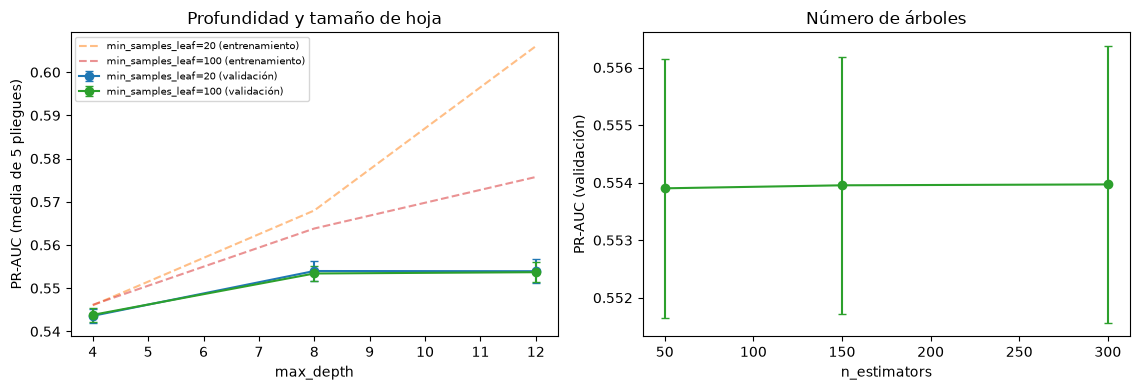

In [15]:
modelo = ModeloPodioRandomForest(umbral=0.5, class_weight="balanced", random_state=SEMILLA)
N_SPLITS = 5
busqueda = modelo.seleccionar_hiperparametros(X_train_imp, y_train, grupos_train, n_splits=N_SPLITS)
display(busqueda["profundidad_hoja"].round(4))
display(busqueda["n_arboles"].round(4))
rutas_graficas["hiperparametros"] = graficas.hiperparametros(busqueda["profundidad_hoja"], busqueda["n_arboles"])

### 4.2 Entrenamiento con la configuración elegida

In [16]:
modelo.entrenar(X_train_imp, y_train, directorio_entrenamiento=ENTRENAMIENTO)
prep.guardar(ENTRENAMIENTO / "preprocesador_podio.pkl")
print("Hiperparámetros elegidos:", modelo.parametros)
display(pd.Series(modelo.hiperparametros_completos(), name="valor").to_frame())

Hiperparámetros elegidos: {'n_estimators': 50, 'max_depth': 8, 'min_samples_leaf': 20}


,valor
bootstrap,True
ccp_alpha,0.0
class_weight,balanced
criterion,gini
max_depth,8
max_features,sqrt
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0
min_samples_leaf,20


### 4.3 Métricas

El objetivo no está tan desbalanceado como un "ganador" (la proporción de positivos se ve en la sección 2.1), pero la exactitud sigue siendo engañosa: responder siempre "fuera del podio" ya acierta la proporción de negativos. Se usan:

- **Precisión:** de los caballos que el modelo marca como podio, cuántos lo son (costo de un falso positivo: apuesta perdida).
- **Recall:** de los que realmente hacen podio, cuántos detecta (costo de un falso negativo: oportunidad perdida).
- **F1, ROC-AUC y PR-AUC:** equilibrio y capacidad de ordenar sin depender del umbral.
- **Precisión top-k por carrera:** de los 3 caballos mejor puntuados en cada carrera, cuántos hacen podio; es la métrica más cercana a la decisión del analista.

In [17]:
prob_train = modelo.predecir_probabilidad(X_train_imp)
prob_test = modelo.predecir_probabilidad(X_test_imp)
metricas_train = modelo.evaluar(X_train_imp, y_train, grupos_train, probabilidades=prob_train)
metricas_test = modelo.evaluar(X_test_imp, y_test, grupos_test, probabilidades=prob_test)
baseline = modelo.baseline_mercado(X_test_imp, y_test)
claves = ["exactitud", "exactitud_baseline", "exactitud_balanceada", "precision", "recall", "f1", "roc_auc", "pr_auc", "pr_auc_azar"]
display(pd.DataFrame({"entrenamiento": {k: metricas_train[k] for k in claves},
                      "prueba": {k: metricas_test[k] for k in claves}}).round(3))
print("Referencia (solo mercado, prueba):", {k: round(v, 3) for k, v in baseline.items()})

,entrenamiento,prueba
exactitud,0.687,0.679
exactitud_baseline,0.724,0.724
exactitud_balanceada,0.698,0.690
precision,0.458,0.449
recall,0.721,0.712
f1,0.560,0.551
roc_auc,0.771,0.760
pr_auc,0.566,0.548
pr_auc_azar,0.276,0.276


Referencia (solo mercado, prueba): {'roc_auc': 0.754, 'pr_auc': 0.531}


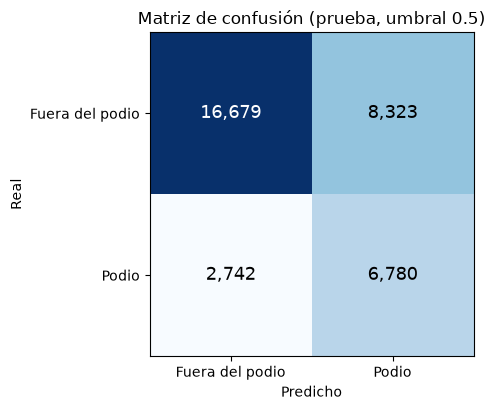

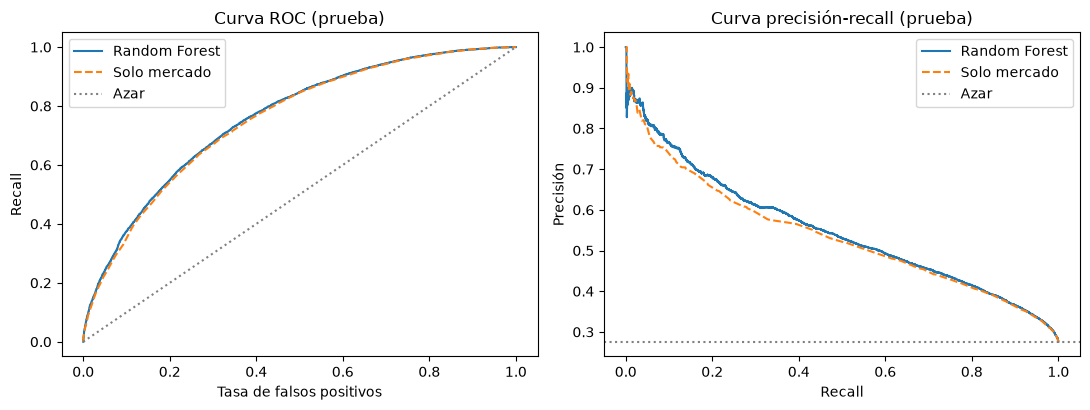

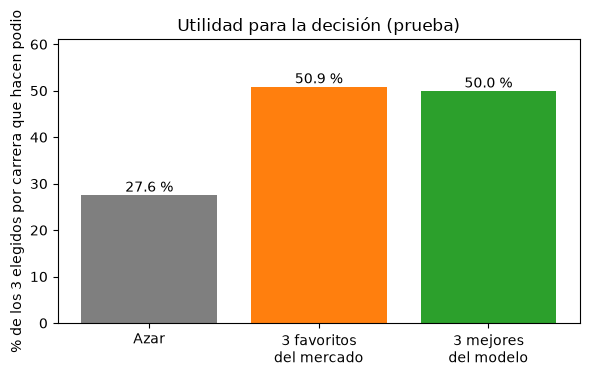

In [18]:
rutas_graficas["matriz_confusion"] = graficas.matriz_confusion(metricas_test["matriz_confusion"], metricas_test["umbral"])
rutas_graficas["curvas"] = graficas.curvas(y_test, prob_test, X_test_imp["decimalPrice"].to_numpy())
rutas_graficas["top_k"] = graficas.top_k(metricas_test)

### 4.4 Qué variables pesan, calibración y desempeño por tamaño de campo

/workspaces/ML_2026_IUD/src/clases_po/modelo_random_forest.py:334: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  tabla["peso_relativo_pct"] = positivos / positivos.sum() * 100 if positivos.sum() > 0 else 0.0


,importancia_impureza,importancia_permutacion,permutacion_desv,peso_relativo_pct
prob_mercado_norm,0.3823,0.0771,0.0046,41.3982
decimalPrice,0.2920,0.0700,0.0051,37.5759
rank_mercado,0.2473,0.0243,0.0028,13.0428
runners,0.0360,0.0138,0.0009,7.3933
OR_rel,0.0100,0.0009,0.0006,0.4747
weight_rel,0.0109,0.0002,0.0003,0.1123
age,0.0031,0.0000,0.0004,0.0028
OR,0.0058,-0.0000,0.0004,0.0000
OR_faltante,0.0017,-0.0002,0.0003,0.0000
saddle,0.0069,-0.0002,0.0001,0.0000


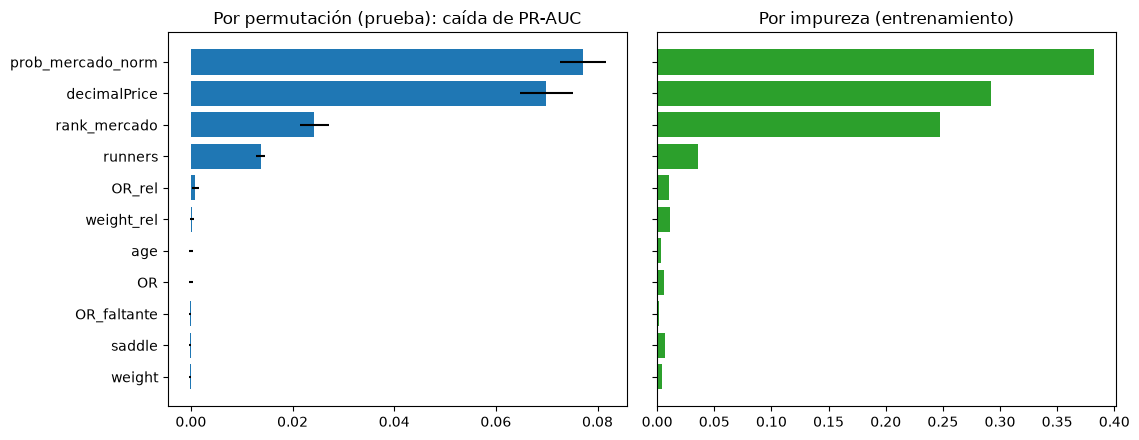

In [19]:
importancias = modelo.importancia_variables(X_test_imp, y_test)
display(importancias.round(4))
rutas_graficas["importancias"] = graficas.importancias(importancias)

/workspaces/ML_2026_IUD/src/clases_po/modelo_random_forest.py:285: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  tabla["decil"] = pd.qcut(tabla["p"].rank(method="first"), grupos_cuantiles, labels=False) + 1
/workspaces/ML_2026_IUD/src/clases

,filas,prob_predicha,tasa_real,diferencia
decil,,,,
1,3453,0.081,0.032,0.049
2,3452,0.185,0.082,0.103
3,3452,0.273,0.126,0.147
4,3453,0.356,0.173,0.183
5,3452,0.429,0.215,0.214
6,3452,0.492,0.276,0.216
7,3453,0.557,0.325,0.232
8,3452,0.626,0.393,0.233
9,3452,0.706,0.484,0.222


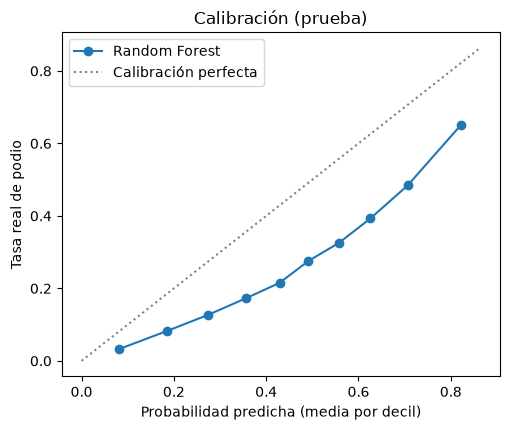

,filas,tasa_podio,roc_auc,pr_auc
corredores,,,,
≤7,5595,0.320,0.752,0.594
8-11,12629,0.319,0.753,0.580
12-15,11416,0.228,0.758,0.494
16+,4884,0.225,0.749,0.474


,predichos_positivos,precision,recall,f1
umbral,,,,
0.2,28777,0.321,0.970,0.482
0.3,24987,0.352,0.925,0.510
0.4,20471,0.393,0.845,0.536
0.5,15103,0.449,0.712,0.551
0.6,10027,0.514,0.541,0.527
0.7,5492,0.602,0.347,0.441


In [20]:
calibracion = modelo.calibracion(y_test, prob_test)
display(calibracion.round(3))
rutas_graficas["calibracion"] = graficas.calibracion(calibracion)
desempeno_campo = modelo.desempeno_por_campo(X_test_imp, y_test, prob_test)
display(desempeno_campo.round(3))
sensibilidad = modelo.sensibilidad_umbral(y_test, prob_test)
display(sensibilidad.round(3))

## 5. Resumen automático `.txt` y documento de hallazgos

Todo se genera por código a partir de esta ejecución: el `.txt` con el resumen, el documento de hallazgos (`hallazgos_ea3.md`) y la sección de hallazgos del `README.md`.

In [21]:
resultados = ConsolidadorEA3.consolidar(
    datos=datos, df_original=df, prep=prep, comparacion=comparacion, distribucion=distribucion,
    modelo=modelo, busqueda=busqueda, n_splits=N_SPLITS,
    metricas_train=metricas_train, metricas_test=metricas_test, baseline=baseline,
    calibracion=calibracion, desempeno_campo=desempeno_campo, sensibilidad=sensibilidad,
    importancias=importancias, graficas=rutas_graficas,
)
resultados = ConsolidadorEA3.agregar_interpretacion(resultados)
AlmacenResultados(SALIDA).guardar("ea3", resultados)
display(Markdown("### Respuesta a la pregunta de negocio\n\n" + resultados["respuesta_negocio"]))
display(Markdown("### Interpretación\n\n" + "\n".join(f"- {l}" for l in resultados["interpretacion"])))
display(Markdown("### Limitaciones\n\n" + "\n".join(f"- {l}" for l in resultados["limitaciones"])))
display(Markdown("### Recomendaciones\n\n" + "\n".join(f"{i}. {l}" for i, l in enumerate(resultados["recomendaciones"], 1))))

### Respuesta a la pregunta de negocio

Sí es posible anticipar parcialmente qué caballos hacen podio. Los factores que más lo determinan son prob_mercado_norm, decimalPrice, rank_mercado. El modelo acierta 50,0 % de los 3 caballos que propone por carrera (azar: 27,6 %; favoritos del mercado: 50,9 %), por lo que sirve como apoyo para priorizar apuestas de colocado, pero no como garantía de acierto.

### Interpretación

- En datos que el modelo no vio, ordena a los caballos con ROC-AUC 0,760 (0,5 sería azar) y PR-AUC 0,548 frente a 0,276 del azar.
- Con el umbral 0,50, de cada 100 caballos que marca como podio acierta 45 % (precisión) y detecta 71 % de los que realmente hacen podio (recall); F1 = 0,551.
- Matriz de confusión: 6.780 aciertos de podio. 8.323 falsas alarmas. 2.742 podios no detectados y 16.679 descartes correctos.
- Dentro de cada carrera, de los 3 caballos mejor puntuados por el modelo el 50,0 % termina en podio; con los 3 favoritos del mercado es 50,9 % y al azar 27,6 %.
- El modelo casi no mejora al mercado solo (ROC-AUC 0,754 frente a 0,760): el precio ya resume casi toda la información disponible.
- Entre entrenamiento y prueba la PR-AUC pasa de 0,566 a 0,548 (diferencia pequeña: no hay sobreajuste importante).
- Variables que más pesan (por permutación): prob_mercado_norm (41,4 %), decimalPrice (37,6 %), rank_mercado (13,0 %).

### Limitaciones

- Solo usa información previa a la carrera y disponible en el dataset (2019): no incluye estado del terreno, distancia de la carrera, forma reciente del caballo ni historial del jinete o del entrenador.
- Un 41 % de los ratings OR venía imputado con la media por el autor del dataset; se devolvieron a nulo y se rellenaron con la mediana del entrenamiento, por lo que el rating es menos informativo de lo que sería con datos completos.
- La precisión con el umbral 0,50 es 45 %: el 55 % de los caballos señalados no hace podio. Una apuesta basada en el modelo sigue teniendo alto riesgo de pérdida.
- Las probabilidades no están perfectamente calibradas: la mayor diferencia entre lo predicho y lo real por decil es de 23,3 puntos porcentuales (el modelo usa class_weight='balanced', que infla las probabilidades de la clase positiva). Úsense para ordenar, no como probabilidad literal.
- El resultado depende de la partición de carreras elegida (semilla 42); con otra partición las métricas variarían ligeramente.
- El modelo no considera cuotas finales de pago ni costos de apuesta: no mide rentabilidad, solo qué tan bien identifica a quienes hacen podio.
- El desempeño cambia según el tamaño del campo; es más débil en carreras de 16+ corredores.

### Recomendaciones

1. Usar el modelo para **ordenar** a los caballos dentro de cada carrera y revisar primero a los 3 mejor puntuados, en lugar de decidir con un umbral fijo de probabilidad.
2. No abandonar la regla simple de los 3 favoritos del mercado solo por este modelo: su ventaja por carrera es mínima (50,0 % vs 50,9 %). Úsese como segunda opinión.
3. Fuera del mercado, vigilar primero **runners**, la variable no-mercado con más peso en el modelo.
4. Antes de arriesgar dinero real, probar el modelo con carreras de otra temporada y medir la rentabilidad con cuotas reales; este análisis solo mide aciertos de podio.
5. Mejorar los datos: completar el rating OR sin imputar y añadir terreno, distancia de la carrera y forma reciente.

In [22]:
reporte = ReporteEA3(SALIDA)
ruta_resumen = reporte.generar_resumen(resultados)
ruta_hallazgos = reporte.generar_hallazgos(resultados)
reporte.actualizar_readme(ROOT / "README.md", resultados, prefijo_imagenes="src/sincronicas/resultados_ea3/graficas/")
print("Resumen:", ruta_resumen)
print("Hallazgos:", ruta_hallazgos)
print()
print(ruta_resumen.read_text(encoding="utf-8"))

Resumen: /workspaces/ML_2026_IUD/src/sincronicas/resultados_ea3/resumen_ea3.txt
Hallazgos: /workspaces/ML_2026_IUD/src/sincronicas/resultados_ea3/hallazgos_ea3.md

RESUMEN DE EJECUCIÓN - EA3: APRENDIZAJE SUPERVISADO (RANDOM FOREST)
Fecha de ejecución: 2026-11-08T22:45:48

1. PREGUNTA DE NEGOCIO
  Pregunta: ¿Qué factores conocidos antes de la salida determinan que un caballo termine en posición
    de pago (podio), para que un analista de apuestas hípicas decida a qué caballos de cada carrera
    dar prioridad en sus apuestas de colocado?
  Quién se beneficia: Un analista o apostador de carreras de caballos que debe repartir un
    presupuesto limitado entre los caballos de cada carrera.
  Decisión que apoya: Elegir, antes de cada carrera, qué caballos merecen una apuesta de colocado y
    cuáles factores (mercado, rating, peso, edad, tamaño del campo) pesan más en esa elección.

2. DATASET
  Identificador : mayacheruty/Horse-Race-Prediction-EDA
  Enlace        : https://huggingface.co/